# D04 — Estrategias de volatilidad, swaps de varianza y dividendos

**Objetivos:** leer las griegas de las estrategias habituales (straddle, strangle, spreads, risk reversal,
mariposa, calendario); replicar un swap de varianza con opciones y entender por qué su strike supera a la
volatilidad ATM; medir la convexidad de un swap de volatilidad; extraer dividendos implícitos y entender por qué
los futuros de dividendos cotizan por debajo de las previsiones; asesorar a un fondo de pensiones que quiere
cobrar primas de riesgo de volatilidad y de dividendos.

**Fuentes:** Hull cap. 12 (estrategias) y 26.16 (swaps de varianza); Demeterfi, Derman, Kamal y Zou, *A Guide to
Volatility and Variance Swaps* (1999); Schofield, *Equity Derivatives*, cap. 6, 12 (12.2 y 12.7.3), 13 (13.2, 13.4,
13.5.8 y 13.5.9) y 14. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves
from derivlab.equity import (EquityMarket, SSVI, bs_price, bs_greeks, local_vol_mc, var_swap_strike, vol_swap_approx,
                             implied_dividend_pv, dividend_future_value)
from derivlab import equity_market as em

estr, eur = build_curves(sample_market())
mkt = EquityMarket(estr)
surface = SSVI()

## 1. Estrategias de volatilidad y sus griegas

Cada estrategia es una apuesta sobre algo distinto: el nivel de la volatilidad (vega), su realización (gamma), el
skew (vanna), la curvatura del smile (volga) o la estructura temporal (calendario). Las griegas se suman pata a
pata con la volatilidad de cada strike en la superficie. Cifras por una vez el índice, plazo un año salvo el
calendario.

In [2]:
T = 1.0
F1, df1 = mkt.forward(T), mkt.P(T)
S = mkt.spot

def leg(K, call, qty, T_=T):
    v = float(surface.vol_strike(mkt, K, T_))
    g = bs_greeks(mkt, K, T_, v, call=call)
    return {k: qty * g[k] for k in ["price", "delta", "gamma", "vega", "theta", "vanna", "volga"]}

def combine(legs):
    out = {}
    for l in legs:
        for k, v in l.items():
            out[k] = out.get(k, 0.0) + v
    return out

strategies = {
    "long straddle 100": [leg(S, True, 1), leg(S, False, 1)],
    "long strangle 90/110": [leg(0.9 * S, False, 1), leg(1.1 * S, True, 1)],
    "call spread 100/110": [leg(S, True, 1), leg(1.1 * S, True, -1)],
    "put spread 100/90": [leg(S, False, 1), leg(0.9 * S, False, -1)],
    "risk reversal: long 110c, short 90p": [leg(1.1 * S, True, 1), leg(0.9 * S, False, -1)],
    "butterfly 90/100/110 (calls)": [leg(0.9 * S, True, 1), leg(S, True, -2), leg(1.1 * S, True, 1)],
    "calendar: long 1y, short 3m ATM call": [leg(S, True, 1), leg(S, True, -1, 0.25)],
}
greeks = pd.DataFrame({name: combine(legs) for name, legs in strategies.items()}).T
greeks["gamma"] *= 1000
print("Per one unit of the index (gamma x 1,000; vega, vanna and volga per vol point; theta per day)")
print(greeks.round(3).to_string())
print(f"CASE straddle: price {greeks.loc['long straddle 100', 'price']:.0f} points ({greeks.loc['long straddle 100', 'price'] / S:.1%}), "
      f"vega {greeks.loc['long straddle 100', 'vega']:.1f}, theta {greeks.loc['long straddle 100', 'theta']:.2f} per day")

Per one unit of the index (gamma x 1,000; vega, vanna and volga per vol point; theta per day)
                                        price  delta  gamma    vega  theta  vanna  volga
long straddle 100                     651.384 -0.019  0.985  38.439 -0.843  0.009  0.011
long strangle 90/110                  281.148 -0.068  0.807  31.157 -0.700  0.013  0.854
call spread 100/110                   199.708  0.263  0.044   4.693 -0.210 -0.015 -0.695
put spread 100/90                     170.527 -0.214  0.135   2.588  0.067  0.010 -0.148
risk reversal: long 110c, short 90p  -116.823  0.521  0.091  -2.105  0.062  0.025  0.547
butterfly 90/100/110 (calls)          120.427 -0.049 -0.178  -7.282  0.168  0.004  0.843
calendar: long 1y, short 3m ATM call  110.065 -0.046 -0.484   9.293  0.466  0.005  0.005
CASE straddle: price 651 points (13.0%), vega 38.4, theta -0.84 per day


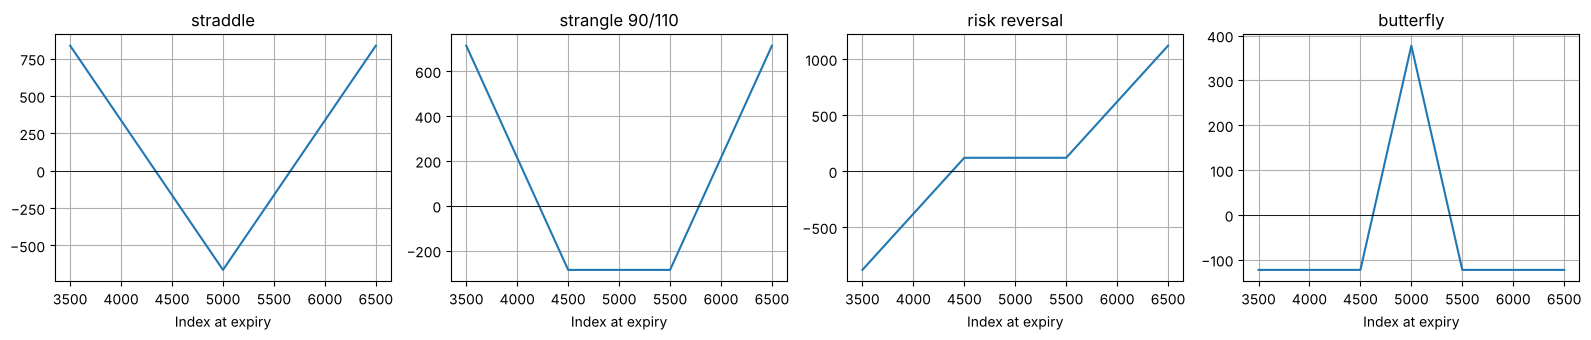

In [3]:
ST = np.linspace(3500, 6500, 301)
pay = {
    "straddle": np.abs(ST - S),
    "strangle 90/110": np.maximum(0.9 * S - ST, 0) + np.maximum(ST - 1.1 * S, 0),
    "risk reversal": np.maximum(ST - 1.1 * S, 0) - np.maximum(0.9 * S - ST, 0),
    "butterfly": np.maximum(ST - 0.9 * S, 0) - 2 * np.maximum(ST - S, 0) + np.maximum(ST - 1.1 * S, 0),
}
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
cost = {"straddle": "long straddle 100", "strangle 90/110": "long strangle 90/110",
        "risk reversal": "risk reversal: long 110c, short 90p", "butterfly": "butterfly 90/100/110 (calls)"}
for a, (name, p) in zip(ax, pay.items()):
    a.plot(ST, p - greeks.loc[cost[name], "price"] / df1)
    a.axhline(0, color="k", lw=0.6); a.set_title(name); a.set_xlabel("Index at expiry")
plt.tight_layout(); plt.show()

**Lectura.**

- El straddle es la apuesta pura a volatilidad: delta casi nula, gamma y vega máximas, y paga theta cada día.
- El risk reversal largo call / corto put tiene delta positiva y vega casi nula, pero vanna positiva: es una
  apuesta a que el skew se aplane. Es lo contrario de lo que hacía el hedge fund de D03.
- La mariposa es corta gamma y vega en el centro y larga volga: gana si el índice termina cerca de 5.000 y si la
  curvatura del smile sube.
- El calendario es largo vega a un año y corto gamma a tres meses: gana si sube la volatilidad larga sin que el
  índice se mueva mucho.

## 2. Swaps de varianza: replicación y strike

Un swap de varianza paga $N_{var}\,(\sigma^2_{\text{realizada}} - K_{var})$. Con difusión continua, la varianza
realizada es $\int_0^T \sigma_t^2 dt = 2\left(\int_0^T \frac{dF_t}{F_t} - \ln\frac{F_T}{F_0}\right)$: un contrato
logarítmico más una cobertura delta. El contrato logarítmico se replica con opciones fuera del dinero
(Hull 26.16, Demeterfi et al.):
$$K_{var} = \frac{2}{T}\left[\int_0^{F} \frac{P(K)}{K^2}dK + \int_{F}^{\infty}\frac{C(K)}{K^2}dK\right]$$
(precios sin descontar). Los puts de strike bajo pesan $1/K^2$: con skew, el strike de varianza queda por encima
de la volatilidad ATM. Se suele cotizar en volatilidad, $\sqrt{K_{var}}$, y el nocional en *vega*:
$N_{var} = N_{vega} / (2\sqrt{K_{var}})$ con volatilidades en puntos.

In [4]:
rows = []
for T_ in [0.25, 0.5, 1.0, 2.0, 3.0, 5.0]:
    F_ = mkt.forward(T_)
    kv = var_swap_strike(lambda K: surface.vol(np.log(K / F_), T_), T_, F_)
    rows.append({"T": T_, "ATM vol": float(surface.vol(0.0, T_)), "var swap vol": np.sqrt(kv), "K_var": kv})
vs = pd.DataFrame(rows)
vs["spread (pts)"] = (vs["var swap vol"] - vs["ATM vol"]) * 100
vs["forward vol"] = np.r_[vs["var swap vol"][0], np.sqrt(np.diff(vs.K_var * vs["T"]) / np.diff(vs["T"]))]
print(vs.to_string(index=False, formatters={"ATM vol": "{:.2%}".format, "var swap vol": "{:.2%}".format,
      "K_var": "{:.4f}".format, "spread (pts)": "{:.1f}".format, "forward vol": "{:.2%}".format}))
kv1 = float(vs.K_var[vs["T"] == 1.0].iloc[0])
print(f"CASE 1y variance swap strike {np.sqrt(kv1):.2%} vs ATM {surface.vol(0.0, 1.0):.2%}")

   T ATM vol var swap vol  K_var spread (pts) forward vol
0.25  16.03%       18.07% 0.0327          2.0      18.07%
0.50  16.50%       18.87% 0.0356          2.4      19.63%
1.00  17.27%       20.13% 0.0405          2.9      21.33%
2.00  18.34%       21.92% 0.0481          3.6      23.58%
3.00  19.00%       23.06% 0.0532          4.1      25.19%
5.00  19.63%       24.23% 0.0587          4.6      25.87%
CASE 1y variance swap strike 20.13% vs ATM 17.27%


In [5]:
F_ = F1
ks = F_ * np.exp(np.linspace(-3.0, 1.5, 4001))
vols = surface.vol(np.log(ks / F_), 1.0)
otm = np.where(ks < F_, bs_price(F_, ks, 1.0, vols, 1.0, call=False), bs_price(F_, ks, 1.0, vols, 1.0, call=True))
contrib = 2.0 * otm / ks ** 2
buckets = [(0, 0.7), (0.7, 0.85), (0.85, 1.0), (1.0, 1.15), (1.15, 10)]
share = []
for lo, hi in buckets:
    m = (ks / F_ >= lo) & (ks / F_ < hi)
    share.append({"strikes (K/F)": f"{lo:.2f}-{hi:.2f}", "share of K_var": np.trapezoid(contrib[m], ks[m]) / kv1})
print(pd.DataFrame(share).to_string(index=False, formatters={"share of K_var": "{:.1%}".format}))
flat = np.trapezoid(2.0 * np.where(ks < F_, bs_price(F_, ks, 1.0, 0.1727, 1.0, False), bs_price(F_, ks, 1.0, 0.1727, 1.0, True)) / ks ** 2, ks)
print(f"Same replication with a flat 17.27% smile: sqrt(K_var) = {np.sqrt(flat):.2%} (the skew adds {(np.sqrt(kv1) - np.sqrt(flat)) * 100:.1f} pts)")

strikes (K/F) share of K_var
    0.00-0.70          16.4%
    0.70-0.85          20.4%
    0.85-1.00          37.8%
    1.00-1.15          22.8%
   1.15-10.00           1.9%
Same replication with a flat 17.27% smile: sqrt(K_var) = 17.27% (the skew adds 2.9 pts)


### Comprobación con la volatilidad local y el swap de volatilidad

En volatilidad local (una difusión que reprecia todas las vanillas) la varianza realizada media debe coincidir con
$K_{var}$. Además la simulación da la distribución completa de la volatilidad realizada, y con ella el strike de un
swap de volatilidad, $E[\sigma_{\text{realizada}}] = E[\sqrt{V}] < \sqrt{E[V]}$ (desigualdad de Jensen). La
aproximación de segundo orden es $E[\sqrt V] \approx \sqrt{E V} - \operatorname{Var}(V) / (8 (E V)^{3/2})$.

CASE E[realised variance] 0.04045 vs K_var 0.04054 (-0.21%)
CASE vol swap strike 18.76% vs variance swap 20.13% (convexity 1.4 pts); second-order approximation 18.02%


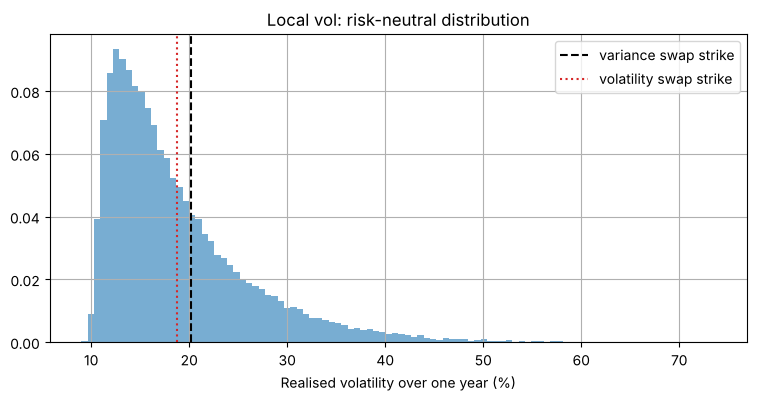

In [6]:
obs = np.arange(1, 253) / 252
_, X = local_vol_mc(surface, 1.0, n_paths=40000, seed=11, obs_times=obs)
X = np.hstack([np.zeros((X.shape[0], 1)), X])
rv = np.sum(np.diff(X, axis=1) ** 2, axis=1)          # annualised realised variance over one year, daily returns
vol_real = np.sqrt(rv)
vol_swap_mc = vol_real.mean()
vol_swap_2nd = vol_swap_approx(rv.mean(), rv.var())
print(f"CASE E[realised variance] {rv.mean():.5f} vs K_var {kv1:.5f} ({rv.mean() / kv1 - 1:+.2%})")
print(f"CASE vol swap strike {vol_swap_mc:.2%} vs variance swap {np.sqrt(kv1):.2%} (convexity {(np.sqrt(kv1) - vol_swap_mc) * 100:.1f} pts); "
      f"second-order approximation {vol_swap_2nd:.2%}")
plt.hist(vol_real * 100, bins=100, density=True, alpha=0.6)
plt.axvline(np.sqrt(kv1) * 100, color="k", ls="--", label="variance swap strike")
plt.axvline(vol_swap_mc * 100, color="C3", ls=":", label="volatility swap strike")
plt.xlabel("Realised volatility over one year (%)"); plt.legend(); plt.title("Local vol: risk-neutral distribution"); plt.show()

**Lectura.** La varianza realizada media reproduce el strike replicado, como debe ser. La distribución de la
volatilidad realizada es muy asimétrica (la volatilidad local es alta cuando cae el índice), así que la convexidad
del swap de volatilidad es de más de un punto y la aproximación de segundo orden se queda corta: hace falta un
modelo de volatilidad de la volatilidad para dar precio a un swap de volatilidad, mientras que el de varianza solo
necesita las vanillas.

## 3. Dividendos: futuros, dividendos implícitos y prima de riesgo

Un futuro de dividendos sobre el índice liquida, en diciembre de cada año, los dividendos pagados por el índice
ese año (en el contrato de Eurex sobre el EURO STOXX 50, 100 € por punto). La paridad put-call da otra lectura
de los mismos dividendos: $C - P = P(0,T)(F - K)$ fija el forward, y con él
$\text{PV}(\text{div}) = S - F\,P(0,T)\,e^{q_{\text{repo}}T}$.

Los futuros cotizan por debajo de lo que esperan los analistas. Schofield (13.2 y 12.7.3.2) explica por qué: el
negocio de productos estructurados deja a los bancos largos dividendos (cortos calls en notas de capital
protegido, largos puts en *reverse convertibles* y *autocallables*), y para cubrirse venden futuros de
dividendos de plazo largo. Esa presión vendedora deja la curva con pendiente negativa y por debajo de su valor
fundamental: quien compra cobra una prima por asumir el riesgo de recortes.

 year  futures (market)  analysts  gap (points) gap (%)
 2027             168.0     172.0           4.0    2.4%
 2028             165.0     178.0          13.0    7.9%
 2029             160.0     184.0          24.0   15.0%
 2030             155.0     190.0          35.0   22.6%
 2031             152.0     196.0          44.0   28.9%
 2032             150.0     202.0          52.0   34.7%


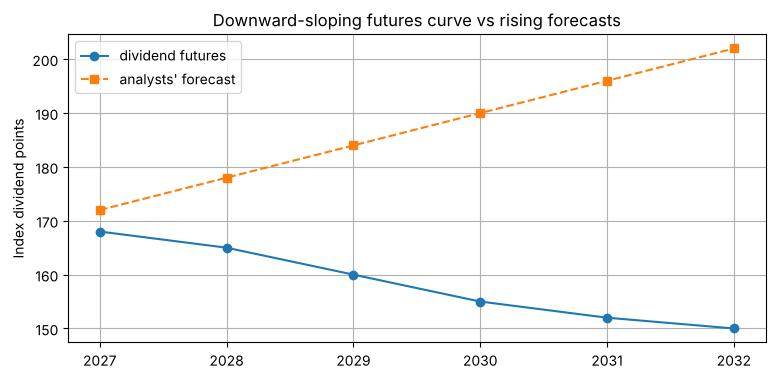

  T   call    put  implied PV dividends  PV of futures dividends
1.0 281.87 369.51                166.54                   166.54
2.0 390.56 553.03                327.43                   327.43
3.0 468.39 688.96                480.53                   480.53
CASE 2028 future 165 vs analysts 178; 2031 future 152 vs analysts 196: the discount grows with maturity


In [7]:
dv = pd.DataFrame({"year": em.DIVIDEND_YEARS, "futures (market)": em.DIVIDENDS_MARKET, "analysts": em.DIVIDENDS_FORECAST})
dv["gap (points)"] = dv["analysts"] - dv["futures (market)"]
dv["gap (%)"] = dv["gap (points)"] / dv["futures (market)"]
print(dv.to_string(index=False, formatters={"gap (%)": "{:.1%}".format}))
plt.plot(dv.year, dv["futures (market)"], "o-", label="dividend futures")
plt.plot(dv.year, dv.analysts, "s--", label="analysts' forecast")
plt.ylabel("Index dividend points"); plt.legend(); plt.title("Downward-sloping futures curve vs rising forecasts"); plt.show()

impl = []
for T_ in [1.0, 2.0, 3.0]:
    F_, df_ = mkt.forward(T_), mkt.P(T_)
    K = 5000.0
    v = float(surface.vol_strike(mkt, K, T_))
    c, p = bs_price(F_, K, T_, v, df_, True), bs_price(F_, K, T_, v, df_, False)
    impl.append({"T": T_, "call": c, "put": p, "implied PV dividends": implied_dividend_pv(mkt, T_, c, p, K),
                 "PV of futures dividends": mkt.pv_dividends(T_)})
impl = pd.DataFrame(impl)
print(impl.round(2).to_string(index=False))
print(f"CASE 2028 future {em.DIVIDENDS_MARKET[1]:.0f} vs analysts {em.DIVIDENDS_FORECAST[1]:.0f}; "
      f"2031 future {em.DIVIDENDS_MARKET[4]:.0f} vs analysts {em.DIVIDENDS_FORECAST[4]:.0f}: the discount grows with maturity")

Las opciones y los futuros de dividendos cuentan la misma historia porque el desk de opciones usa los dividendos
de los futuros para calcular el forward (D1). Si no lo hiciera, habría un arbitraje entre el forward sintético de
las opciones y el forward con los dividendos de mercado. Cerca del vencimiento los futuros convergen a los
dividendos ya anunciados (*pull to realized*, Schofield 13.5.9).

## 4. Caso: un fondo de pensiones busca primas de riesgo

**Situación.** Un fondo de pensiones de empleo tiene 400 M€ en renta variable europea y un horizonte largo. Busca
rentabilidad adicional que no dependa solo de que suba la bolsa. El banco le propone dos ideas:

- **(A) Comprar futuros de dividendos de 2028** (1.000 contratos, 100.000 € por punto de dividendo), que es la
  exposición que pide el fondo. Cobra la diferencia entre lo que pague el índice en 2028 y lo que descuenta hoy
  el mercado.
- **(B) Vender varianza a un año** con nocional vega de 200.000 € por punto y un *cap* habitual de 2,5 veces el
  strike en volatilidad. Cobra la diferencia entre la volatilidad implícita y la realizada (prima de riesgo de
  volatilidad), a cambio de perder si la realizada se dispara.

El comité de inversiones pregunta: cuánto se gana en el escenario central, cuánto se pierde en un escenario de
crisis y cómo se relaciona cada idea con la cartera que ya tiene.

In [8]:
per_point = 1000 * 100.0                        # 1,000 contracts x 100 EUR per dividend point
i28 = em.DIVIDEND_YEARS.index(2028)
px28, fc28 = em.DIVIDENDS_MARKET[i28], em.DIVIDENDS_FORECAST[i28]
scen_div = {
    f"analysts right ({fc28:.0f})": fc28,
    f"flat at the 2027 level ({em.DIVIDENDS_MARKET[0]:.0f})": em.DIVIDENDS_MARKET[0],
    f"as priced ({px28:.0f})": px28,
    "crisis: 35% cut from priced": 0.65 * px28,
}
idea_a = pd.DataFrame({k: {"realised points": v, "P&L (M EUR)": dividend_future_value(v, px28) * per_point / 1e6}
                       for k, v in scen_div.items()}).T
print(idea_a.round(1))
ladder = dv[["year", "futures (market)", "analysts"]].copy()
ladder["gain per contract if analysts right (EUR)"] = (ladder.analysts - ladder["futures (market)"]) * 100
ladder["loss per contract in a 35% cut (EUR)"] = -0.35 * ladder["futures (market)"] * 100
print(ladder.to_string(index=False))
mtm_10 = 0.10 * px28 * per_point / 1e6
print(f"CASE idea A (2028): +{idea_a.iloc[0, 1]:.1f} M EUR if analysts are right, {idea_a.iloc[-1, 1]:.1f} M EUR in a 35% cut; "
      f"a 10% downward revision costs {mtm_10:.1f} M EUR of mark-to-market today")

                              realised points  P&L (M EUR)
analysts right (178)                    178.0          1.3
flat at the 2027 level (168)            168.0          0.3
as priced (165)                         165.0          0.0
crisis: 35% cut from priced             107.2         -5.8
 year  futures (market)  analysts  gain per contract if analysts right (EUR)  loss per contract in a 35% cut (EUR)
 2027             168.0     172.0                                      400.0                               -5880.0
 2028             165.0     178.0                                     1300.0                               -5775.0
 2029             160.0     184.0                                     2400.0                               -5600.0
 2030             155.0     190.0                                     3500.0                               -5425.0
 2031             152.0     196.0                                     4400.0                               -5320.0
 2032          

In [9]:
K_vol = np.sqrt(kv1) * 100                       # variance swap strike in vol points
N_vega = 200000.0
N_var = N_vega / (2 * K_vol)
cap = 2.5 * K_vol

def short_var_pnl(realised_vol_pts, capped=True):
    rv2 = np.minimum(realised_vol_pts, cap) ** 2 if capped else realised_vol_pts ** 2
    return N_var * (K_vol ** 2 - rv2)

real = [12.0, 15.0, K_vol, 25.0, 35.0, 50.0, 60.0]
idea_b = pd.DataFrame({"realised vol": real,
                       "P&L capped (M EUR)": [short_var_pnl(r) / 1e6 for r in real],
                       "P&L uncapped (M EUR)": [short_var_pnl(r, False) / 1e6 for r in real]})
print(f"strike {K_vol:.2f} vol points; variance notional {N_var:,.0f} EUR per variance point; cap at {cap:.1f} vol")
print(idea_b.round(2).to_string(index=False))
pnl_rn = short_var_pnl(vol_real * 100)
print(f"CASE idea B: +{short_var_pnl(15.0) / 1e6:.2f} M EUR if realised is 15%; {short_var_pnl(60.0) / 1e6:.2f} M at 60% "
      f"(uncapped {short_var_pnl(60.0, False) / 1e6:.2f} M); risk-neutral: gain in {np.mean(pnl_rn > 0):.0%} of paths, "
      f"5% worst {np.quantile(pnl_rn, 0.05) / 1e6:.2f} M EUR")

strike 20.13 vol points; variance notional 4,967 EUR per variance point; cap at 50.3 vol
 realised vol  P&L capped (M EUR)  P&L uncapped (M EUR)
        12.00                1.30                  1.30
        15.00                0.90                  0.90
        20.13                0.00                  0.00
        25.00               -1.09                 -1.09
        35.00               -4.07                 -4.07
        50.00              -10.40                -10.40
        60.00              -10.57                -15.87
CASE idea B: +0.90 M EUR if realised is 15%; -10.57 M at 60% (uncapped -15.87 M); risk-neutral: gain in 68% of paths, 5% worst -3.56 M EUR


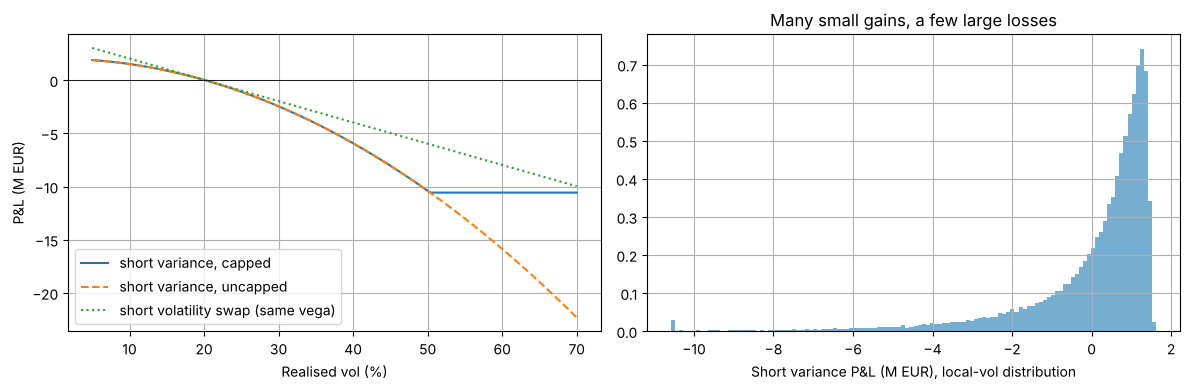

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rv_grid = np.linspace(5, 70, 300)
ax[0].plot(rv_grid, short_var_pnl(rv_grid) / 1e6, label="short variance, capped")
ax[0].plot(rv_grid, short_var_pnl(rv_grid, False) / 1e6, "--", label="short variance, uncapped")
ax[0].plot(rv_grid, N_vega * (K_vol - rv_grid) / 1e6, ":", label="short volatility swap (same vega)")
ax[0].axhline(0, color="k", lw=0.6); ax[0].set_xlabel("Realised vol (%)"); ax[0].set_ylabel("P&L (M EUR)"); ax[0].legend()
ax[1].hist(pnl_rn / 1e6, bins=120, density=True, alpha=0.6)
ax[1].set_xlabel("Short variance P&L (M EUR), local-vol distribution"); ax[1].set_title("Many small gains, a few large losses")
plt.tight_layout(); plt.show()

**Lectura para el comité.**

- **Idea A.** Con las previsiones de los analistas gana 1,3 M€; si los dividendos de 2028 se cumplen tal como
  cotizan, nada; con un recorte del 35 % (una crisis severa, como los recortes de 2009 o 2020) pierde 5,8 M€.
  El descuento crece con el plazo: el futuro de 2031 cotiza un 22 % por debajo de los analistas frente al 7 % del
  de 2028, porque es ahí donde los bancos venden más. La prima existe porque los bancos son vendedores
  estructurales, pero el riesgo es procíclico: los dividendos se recortan cuando cae la bolsa, justo cuando el
  fondo ya pierde en su cartera. No diversifica en la cola.
- **Idea B.** Vender varianza gana poco y a menudo, y pierde mucho de vez en cuando: es estar corto convexidad.
  El *cap* limita la pérdida en un crash. Con la distribución neutral al riesgo el valor esperado es cero por
  construcción; el fondo solo gana en media si la realizada queda por debajo de la implícita, que es lo habitual
  en índices (la prima de riesgo de volatilidad), pero no está garantizado. También es procíclica.
- **Recomendación equilibrada.** Las dos ideas añaden riesgo de cola a una cartera ya larga en renta variable.
  Si el fondo quiere esas primas, tamaño pequeño (por ejemplo, que la pérdida en crisis no supere 25 pb del
  patrimonio), cap obligatorio en la varianza y plazos escalonados en dividendos. Al otro lado suele haber un
  banco que necesita volatilidad larga (está corto calls por notas de capital protegido, Schofield 12.2) o que
  quiere soltar riesgo de dividendos: conviene saber a quién se le hace el favor y cobrarlo.

## 5. Comprobaciones

In [11]:
assert greeks.loc["long straddle 100", "vega"] > 0 and abs(greeks.loc["long straddle 100", "delta"]) < 0.2
assert greeks.loc["butterfly 90/100/110 (calls)", "gamma"] < 0
assert (vs["var swap vol"] > vs["ATM vol"]).all()
assert abs(rv.mean() / kv1 - 1) < 0.01
assert vol_swap_mc < np.sqrt(kv1)
assert np.allclose(impl["implied PV dividends"], impl["PV of futures dividends"], rtol=1e-8)
assert idea_a.loc[f"as priced ({px28:.0f})", "P&L (M EUR)"] == 0
assert short_var_pnl(70.0) == short_var_pnl(cap)
assert abs(np.mean(pnl_rn)) < 0.05 * N_vega * K_vol / 10
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuánto vale hoy, en puntos, la cartera de una call 100 % a un año más un put 100 % a un año? ¿Cuánto
   tiene que moverse el índice al vencimiento para recuperar la prima?
2. **Intermedio.** Calcula el strike de un swap de varianza *forward start* entre uno y dos años y compáralo con la
   volatilidad ATM forward implícita entre esos plazos.
3. **Avanzado.** El fondo prefiere vender un swap de volatilidad en lugar de uno de varianza, con el mismo nocional
   vega. Con la distribución de la volatilidad local, ¿qué strike es justo y cómo cambia la pérdida al 1 %?

## Soluciones

In [12]:
straddle = greeks.loc["long straddle 100", "price"]
print(f"straddle {straddle:.1f} points; breakevens at expiry {S - straddle / df1:,.0f} and {S + straddle / df1:,.0f} "
      f"(a move of {straddle / df1 / S:.1%} either way)")

straddle 651.4 points; breakevens at expiry 4,336 and 5,664 (a move of 13.3% either way)


In [13]:
kv_2 = float(vs.K_var[vs["T"] == 2.0].iloc[0])
fwd_var = (kv_2 * 2.0 - kv1 * 1.0) / 1.0
atm1, atm2 = float(surface.vol(0.0, 1.0)), float(surface.vol(0.0, 2.0))
fwd_atm = np.sqrt((atm2 ** 2 * 2.0 - atm1 ** 2 * 1.0) / 1.0)
print(f"1y-2y forward variance strike {np.sqrt(fwd_var):.2%} vs forward ATM vol {fwd_atm:.2%}: the skew premium also exists forward")

1y-2y forward variance strike 23.58% vs forward ATM vol 19.36%: the skew premium also exists forward


In [14]:
K_volswap = vol_swap_mc * 100
pnl_volswap = N_vega * (K_volswap - vol_real * 100)
print(f"fair vol swap strike {K_volswap:.2f} vs variance strike {K_vol:.2f}")
print(f"1% worst P&L: short vol swap {np.quantile(pnl_volswap, 0.01) / 1e6:.2f} M EUR; "
      f"short capped variance {np.quantile(pnl_rn, 0.01) / 1e6:.2f} M EUR; "
      f"short uncapped variance {np.quantile(short_var_pnl(vol_real * 100, False), 0.01) / 1e6:.2f} M EUR")
print("The vol swap is linear in realised vol, so its tail is smaller, but it is priced off a model of vol of vol.")

fair vol swap strike 18.76 vs variance strike 20.13
1% worst P&L: short vol swap -4.93 M EUR; short capped variance -7.35 M EUR; short uncapped variance -7.35 M EUR
The vol swap is linear in realised vol, so its tail is smaller, but it is priced off a model of vol of vol.
